In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# KMeans
from sklearn.cluster import KMeans
# Preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder
# Metrics
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv('Dataset/Mall_Customers.csv')
df.head(2)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81


In [3]:
sns.boxplot(df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']])
plt.close()

In [4]:
le = LabelEncoder()
df['Gender_Id'] = le.fit_transform(df['Gender'])

## Features

In [28]:
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Gender_Id']
X = df[features]

## Feature Scaling

In [29]:
scaler = StandardScaler()
X_scale = scaler.fit_transform(X)

## Elbow Method

In [30]:
import warnings
warnings.filterwarnings('ignore')

In [31]:
k_range = range(1, 21)
error_rate = []
for i in k_range:
    kmeans = KMeans(n_clusters = i)
    kmeans.fit_predict(X_scale)
    error_rate.append(kmeans.inertia_)

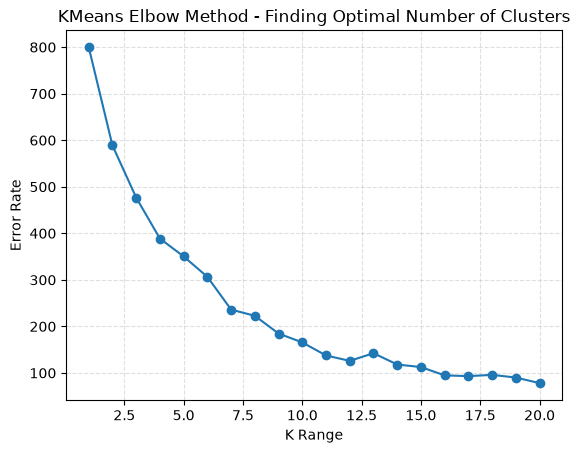

In [32]:
plt.plot(k_range, error_rate, marker='o')
plt.grid(linestyle='dashed', alpha=0.4)
plt.xlabel('K Range')
plt.ylabel('Error Rate')
plt.title('KMeans Elbow Method - Finding Optimal Number of Clusters')
plt.show()

## Model Implementation

In [33]:
k = 6
model = KMeans(n_clusters=k)
clusters = model.fit_predict(X_scale)

## Metric

In [34]:
sc = silhouette_score(X_scale, clusters)
sc

0.3383245459137872

## Visualization

In [35]:
# 'Gender_Id', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)'
df['clusters'] = clusters

In [36]:
sns.scatterplot(data = df, x='Age', y='Spending Score (1-100)', c=clusters)
plt.close()

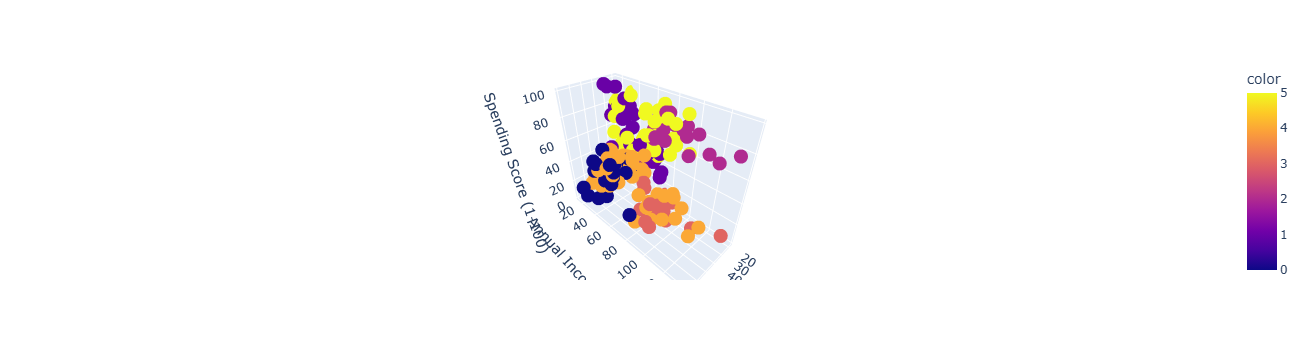

In [37]:
import plotly.express as px

fig = px.scatter_3d(
    df, x='Age', y='Annual Income (k$)', z='Spending Score (1-100)', color=clusters
)
fig.show()

### Principle Component Analysis

In [38]:
from sklearn.decomposition import PCA

In [39]:
pca = PCA(n_components = len(features))

In [40]:
# Co-variance
pca_scale = pca.fit_transform(X_scale)

In [41]:
# Finding important data for axis
loadings = pd.DataFrame(
    pca.components_,
    index=features,
    columns = [f'PC{i+1}' for i in range(len(features))]
)
loadings

,PC1,PC2,PC3,PC4
Age,0.687900,-0.006082,-0.686920,0.234302
Annual Income (k$),-0.103690,0.765252,0.103211,0.626886
Spending Score (1-100),-0.122384,-0.643667,0.136573,0.743009
Gender_Id,0.707859,0.006721,0.706283,-0.007405


In [ ]:
'''
- X-axis -> age, Gender_Id
- Y-axis -> Annual Income (k$), Spending Score (1-100)
'''

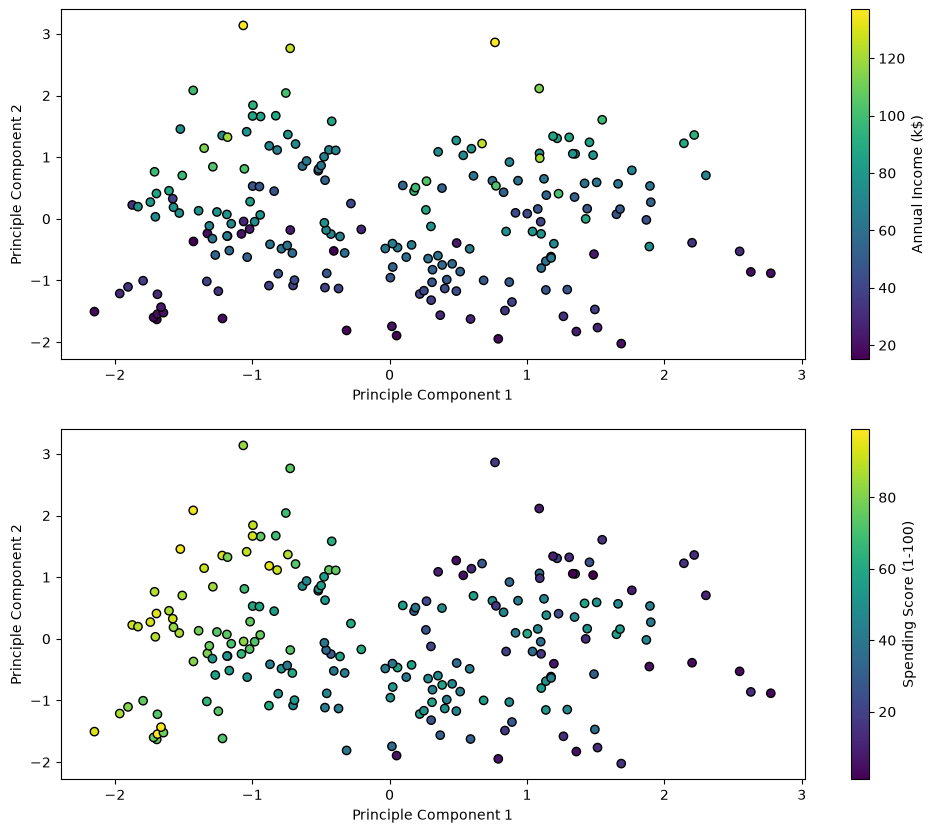

In [45]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

ax1 = axes[0]
color = 'Annual Income (k$)'
scatter = ax1.scatter(pca_scale[:,0], pca_scale[:,1], c=df[color], edgecolor='black')
fig.colorbar(scatter, ax=ax1, label=color)
ax1.set_xlabel('Principle Component 1')
ax1.set_ylabel('Principle Component 2')

ax2 = axes[1]
color = 'Spending Score (1-100)'
scatter = ax2.scatter(pca_scale[:,0], pca_scale[:,1], c=df[color], edgecolor='black')
fig.colorbar(scatter, ax=ax2, label=color)
ax2.set_xlabel('Principle Component 1')
ax2.set_ylabel('Principle Component 2')

plt.show()